# Experiment 12: Weight decay for widths 256 and 512

Card: [exp12_width_weight_decay.md](../../experiments/exp12_width_weight_decay.md)


In [1]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "../../..")  # the ashrae package lives in the homework folder
sys.path.insert(0, "../..")  # the section's src package
from ashrae.config import FOLDS
from ashrae.plots import INK, SURFACE, TEXT, style_axis
from ashrae.tracking import session_runs
from src.data import fold_loaders
from src.networks import MeterMLP
from src.runs import finished_keys, fold_table, session_scores
from src.tracking import Experiment
from src.training import fit_folds

SMOKE = os.environ.get("SMOKE") == "1"
NOTEBOOK = "exp12_width_weight_decay"
EMB_DIM = 12  # picked in exp03
LR = 1e-2
if SMOKE:
    EXPERIMENT = "ashrae-mlp-width-weight-decay-smoke"
    TRAIN = True
    SESSION = None
    FOLD_NAMES = list(FOLDS)[:2]
    N_TRAIN, N_VAL = 20_000, 5_000
    EPOCHS = 3
    WIDTHS = [128]  # the only width the exp10 smoke run trained
    WEIGHT_DECAYS = [0.1]
    # (experiment, session, widths) of the reused runs without weight decay; None: the latest session
    REFERENCES = [
        ("ashrae-mlp-width-smoke", None, WIDTHS),
        ("ashrae-mlp-batch-norm-smoke", None, [64]),
    ]
    FIGURE = None
else:
    EXPERIMENT = "ashrae-mlp-width-weight-decay"
    TRAIN = False  # the runs below are from 2026-10-12; True resumes this session, retraining unfinished runs
    SESSION = "2026-10-12 23:52:14"
    FOLD_NAMES = list(FOLDS)
    N_TRAIN, N_VAL = 2_000_000, 500_000
    EPOCHS = 40
    WIDTHS = [256, 512]
    WEIGHT_DECAYS = [
        0.01,
        0.1,
        1.0,
    ]  # AdamW multiplies decay by lr: 0.1 shrinks weights by 1e-3 per step
    REFERENCES = [
        ("ashrae-mlp-width", "2026-10-12 22:43:11", WIDTHS),  # exp10
        ("ashrae-mlp-batch-norm", "2026-10-12 21:52:51", [64]),  # exp09
    ]
    FIGURE = "../../figures/exp12_width_weight_decay.png"

experiment = Experiment(EXPERIMENT, NOTEBOOK, SESSION)

/Users/lupaskodmitro/FuckIT/Machine Learning/Deep Learning Homeworks/Homework 1 MLP/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


MLflow: sqlite:////Users/lupaskodmitro/FuckIT/Machine Learning/Deep Learning Homeworks/Homework 1 MLP/mlflow.db, experiment 'ashrae-mlp-width-weight-decay', session 2026-10-12 23:52:14


## Training


In [2]:
def scores():
    refs = []
    for name, session, widths in REFERENCES:
        ref = session_runs(name, session)
        ref = ref[ref["params.lr"].astype(float) == LR]
        if "width" in ref:  # exp09 trained width 64 only and has no width tag
            ref = ref[ref.width.astype(int).isin(widths)]
        else:
            ref = ref.assign(width=widths[0])
        refs.append(ref.assign(weight_decay=0.0))
    return session_scores(experiment, {"width": int, "weight_decay": float}, FOLD_NAMES, refs)

In [ ]:
if TRAIN:
    folds, n_buildings, n_features = fold_loaders(FOLD_NAMES, N_TRAIN, N_VAL)
    done = (
        set()
        if SESSION is None
        else finished_keys(scores().query("weight_decay > 0"), ["width", "weight_decay", "fold"])
    )

    for width in WIDTHS:
        for wd in WEIGHT_DECAYS:
            fit_folds(
                experiment,
                folds,
                lambda: MeterMLP(
                    n_features, n_buildings, emb_dim=EMB_DIM, batch_norm=True, width=width
                ),
                f"mlp_4out_emb_bn | width {width} | wd {wd:g}",
                done=done,
                key=(width, wd),
                epochs=EPOCHS,
                lr=LR,
                weight_decay=wd,
                tags={
                    "model": "mlp_4out_emb_bn",
                    "width": str(width),
                    "weight_decay": f"{wd:g}",
                },
                params={"n_train": N_TRAIN, "n_val": N_VAL, "emb_dim": EMB_DIM, "width": width},
            )

## Results


In [3]:
results = scores()
print(f"MLflow session {experiment.session}: {len(results)} runs, with the reused ones")

columns = {
    "val_clean": "average, clean rows",
    "best_epoch": "best epoch",
    "train": "training at best epoch",
    "train_last": f"training at epoch {EPOCHS}",
    "epoch_seconds": "seconds per epoch",
    "minutes_to_best": "minutes to best epoch",
}
table, by_setup = fold_table(results, ["width", "weight_decay"], columns, FOLD_NAMES)
display(table.round(3))

MLflow session 2026-10-12 23:52:14: 36 runs, with the reused ones


RMSLE at the best epoch, all rows unless noted  Jan–Mar  Apr–Jun  Jul–Sep  \
width weight_decay                                                          
64    0.00                                        1.386    1.195    1.008   
256   0.00                                        1.394    1.200    1.012   
      0.01                                        1.397    1.198    1.016   
      0.10                                        1.398    1.204    1.026   
      1.00                                        1.406    1.228    1.088   
512   0.00                                        1.395    1.196    1.013   
      0.01                                        1.397    1.196    1.017   
      0.10                                        1.393    1.203    1.029   
      1.00                                        1.412    1.224    1.082   

RMSLE at the best epoch, all rows unless noted  Oct–Dec  average  \
width weight_decay                                                 
64    0.00                                        1.085    1.168   
256   0.00                                        1.090    1.174   
      0.01                                        1.092    1.176   
      0.10                                        1.092    1.180   
      1.00                                        1.120    1.210   
512   0.00                                        1.091    1.174   
      0.01                                        1.092    1.175   
      0.10                                        1.090    1.179   
      1.00                                        1.115    1.208   

RMSLE at the best epoch, all rows unless noted  average, clean rows  \
width weight_decay                                                    
64    0.00                                                    0.912   
256   0.00                                                    0.911   
      0.01                                                    0.914   
      0.10                                                    0.919   
      1.00                                                    0.981   
512   0.00                                                    0.910   
      0.01                                                    0.917   
      0.10                                                    0.922   
      1.00                                                    0.967   

RMSLE at the best epoch, all rows unless noted  best epoch  \
width weight_decay                                           
64    0.00                                           35.25   
256   0.00                                           15.75   
      0.01                                           11.75   
      0.10                                           23.50   
      1.00                                           16.25   
512   0.00                                           11.75   
      0.01                                           13.50   
      0.10                                           17.50   
      1.00                                           29.00   

RMSLE at the best epoch, all rows unless noted  training at best epoch  \
width weight_decay                                                       
64    0.00                                                       0.761   
256   0.00                                                       0.748   
      0.01                                                       0.761   
      0.10                                                       0.761   
      1.00                                                       0.878   
512   0.00                                                       0.740   
      0.01                                                       0.736   
      0.10                                                       0.760   
      1.00                                                       0.873   

RMSLE at the best epoch, all rows unless noted  training at epoch 40  \
width weight_decay                                 

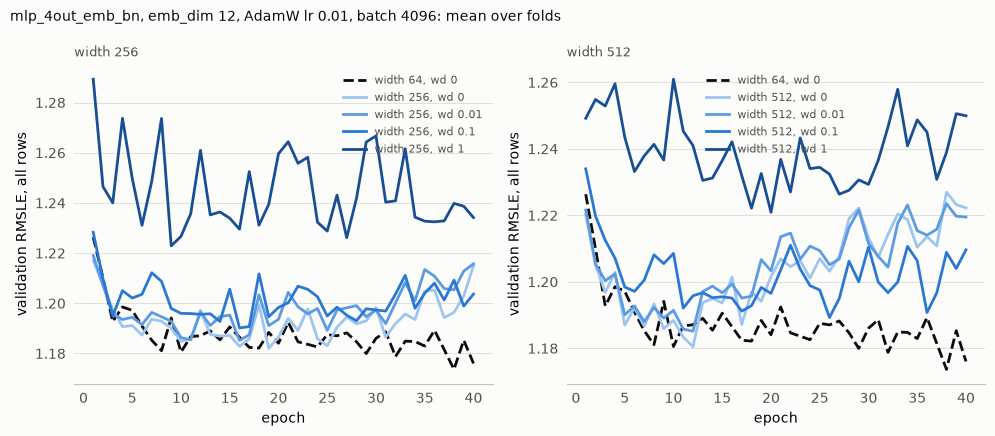

In [ ]:
SHADES = [
    "#9ec5f0",
    "#5b9be3",
    "#2a78d6",
    "#174e94",
]  # light to dark: weight decay 0 to the largest

fig, axes = plt.subplots(
    1, len(WIDTHS), figsize=(5 * len(WIDTHS), 4.4), facecolor=SURFACE, squeeze=False
)
reference = results.query("width == 64")
for col, width in enumerate(WIDTHS):
    groups = [(64, 0.0, reference, INK, "--")] + [
        (width, wd, runs, SHADES[i], "-")
        for i, (wd, runs) in enumerate(
            results.query("width == @width").groupby("weight_decay")
        )
    ]
    ax = axes[0, col]
    for w, wd, runs, color, ls in groups:
        # mean over folds; a diverged run is shorter
        curve = pd.DataFrame(runs.val_curve.tolist()).mean()
        ax.plot(
            np.arange(1, len(curve) + 1),
            curve,
            lw=2,
            color=color,
            ls=ls,
            label=f"width {w}, wd {wd:g}",
        )
    ax.set(xlabel="epoch", ylabel="validation RMSLE, all rows")
    ax.set_title(f"width {width}", loc="left", color=TEXT, fontsize=9)
    style_axis(ax)
    ax.legend(frameon=False, fontsize=8, labelcolor=TEXT)
fig.suptitle(
    f"mlp_4out_emb_bn, emb_dim {EMB_DIM}, AdamW lr {LR:g}, batch 4096: mean over folds",
    x=0.01,
    ha="left",
    color=INK,
    fontsize=10,
)
plt.tight_layout()
if FIGURE:
    fig.savefig(FIGURE, dpi=150, bbox_inches="tight")
    for run_id in results.query("weight_decay > 0").run_id:
        experiment.client.log_artifact(run_id, FIGURE)